In [1]:
import sys
print(sys.executable)

C:\Users\sara9\anaconda3\anaconda\python.exe


In [1]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import Lasso
from sklearn.metrics import mean_squared_error, r2_score, mean_absolute_error

# =========================
# 1. 讀取與清理資料
# =========================
df = pd.read_csv('NBA_Normalized_Final.csv')

bool_cols = ['Is_Undrafted', 'Pos_PG', 'Pos_C', 'Pos_SG', 'Pos_SF', 'Pos_PF']
for col in bool_cols:
    if col in df.columns:
        df[col] = df[col].astype(str).str.upper().map({"TRUE": 1, "FALSE": 0})
target_year=2023

# =========================
# 2. 篩選資料 (三年級 WS 預測)
# =========================
df_g = df[(df['season'] > 1)&(df['year_start']>1999)&(df['year_start']!=target_year) ].copy()

feature_cols = [
    '2P%','2PA','3P','3P%','3PA','3PAr','AST','AST%','BLK','BLK%','BPM','DBPM',
    'DRB','DRB%','DWS','FG','FG%','FGA','FT','FT%','FTA','FTr',
    'OBPM','ORB','ORB%','OWS','PER','PF','PTS','Pos_C','Pos_PF','Pos_PG',
    'Pos_SF','Pos_SG','STL','STL%','TOV','TOV%','TRB','TRB%','TS%','USG%',
    'VORP','WS','WS/48','eFG%'
]
target_col = 'Year3_WS'

# 清洗目標值與特徵值
data = df_g.dropna(subset=[target_col]).copy()
for c in feature_cols:
    data[c] = pd.to_numeric(data[c], errors='coerce')
data[target_col] = pd.to_numeric(data[target_col], errors='coerce')
data = data.dropna(subset=[target_col]).copy()

X = data[feature_cols].copy()
y = data[target_col].copy()

# =========================
# 3. 切分訓練 / 測試 
# =========================
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

# =========================
# 4. 建立 Pipeline 與 GridSearchCV
# =========================

alphas = np.logspace(-4, 1, 40)
cv_splits = min(5, len(X_train))

# 建立管線
pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
    ("lasso", Lasso(max_iter=50000, random_state=42, tol=1e-4))
])

# 使用 GridSearchCV 來自動尋找最佳 alpha
param_grid = {'lasso__alpha': alphas}
grid_search = GridSearchCV(
    pipeline, 
    param_grid, 
    cv=cv_splits, 
    scoring='r2', 
    n_jobs=1
)

grid_search.fit(X_train, y_train)

# =========================
# 5. 計算各項指標
# =========================
# 取出最佳模型
best_model = grid_search.best_estimator_
best_alpha = grid_search.best_params_['lasso__alpha']
best_cv_r2 = grid_search.best_score_

# 預測並計算 R2
train_r2 = r2_score(y_train, best_model.predict(X_train))
test_r2 = r2_score(y_test, best_model.predict(X_test))

# 計算 RMSE 與 MAE
y_pred_test = best_model.predict(X_test)
rmse_test = np.sqrt(mean_squared_error(y_test, y_pred_test))
mae_test = mean_absolute_error(y_test, y_pred_test)

# 提取 Lasso 獨有的「特徵選擇」結果
lasso_coefs = best_model.named_steps["lasso"].coef_
n_total_features = len(feature_cols)
n_retained_features = np.sum(lasso_coefs != 0)

# =========================
# 6. 正式輸出實戰報告
# =========================
print("\n" + "="*45)
print("         LASSO REGRESSION FINAL REPORT")
print("="*45)
print(f"1. Train R² (訓練集得分):   {train_r2:.4f}")
print(f"2. Best CV R² (交叉驗證):  {best_cv_r2:.4f}")
print(f"3. Test R² (實測測試集):   {test_r2:.4f}")
print("-" * 45)
print(f"Chosen Alpha (最佳 λ):     {best_alpha:.4f}")
print(f"Test RMSE:                {rmse_test:.4f}")
print(f"Test MAE:                 {mae_test:.4f}")
print(f"Feature Selection:        保留 {n_retained_features} / {n_total_features} 個特徵")
print("="*45)

# =========================
# 7. 顯示被 Lasso 保留的關鍵特徵
# =========================
coef_df = pd.DataFrame({"feature": feature_cols, "coef": lasso_coefs})
coef_df["abs_coef"] = coef_df["coef"].abs()


active_features = coef_df[coef_df["coef"] != 0].sort_values("abs_coef", ascending=False)

print(active_features[["feature", "coef"]].head(15).to_string(index=False))

C:\Users\sara9\AppData\Roaming\Python\Python313\site-packages\pandas\core\computation\expressions.py:22: UserWarning: Pandas requires version '2.10.2' or newer of 'numexpr' (version '2.10.1' currently installed).
  from pandas.core.computation.check import NUMEXPR_INSTALLED
C:\Users\sara9\AppData\Roaming\Python\Python313\site-packages\sklearn\linear_model\_coordinate_descent.py:840: ConvergenceWarning: Objective did not converge. You might want to increase the number of iterations, check the scale of the features or consider increasing regularisation. Duality gap: 3.829485e+00, tolerance: 5.486e-01
  model = cd_fast.enet_coordinate_descent(
C:\Users\sara9\AppData\Roaming\Python\Python313\site-packages\sklearn\linear_model\_coordinate_descent.py:840: ConvergenceWarning: Objective did not converge. You might want to increase the number of iterations, check the scale of the features or consider increasing regularisation. Duality gap: 3.859159e+01, tolerance: 5.701e-01
  model = cd_fast.en


         LASSO REGRESSION FINAL REPORT
1. Train R² (訓練集得分):   0.5682
2. Best CV R² (交叉驗證):  0.5357
3. Test R² (實測測試集):   0.6336
---------------------------------------------
Chosen Alpha (最佳 λ):     0.0367
Test RMSE:                1.7505
Test MAE:                 1.2784
Feature Selection:        保留 15 / 46 個特徵
feature      coef
     WS  1.308112
     FT  0.472777
    DWS  0.196722
   VORP  0.187444
     PF -0.130360
 Pos_SG  0.092174
   TRB%  0.079873
    ORB  0.072559
   AST%  0.070737
     3P -0.062702
    3P% -0.046965
    FT% -0.037723
    AST  0.012779
    2P%  0.006085
  Pos_C -0.004405


In [20]:
import numpy as np
from sklearn.linear_model import Lasso
from sklearn.model_selection import train_test_split, KFold, cross_val_score
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.metrics import mean_squared_error, mean_absolute_error, median_absolute_error

# -------------------------
# 1) 切 train/test
# -------------------------
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42
)

# -------------------------
# 2) 建立 Lasso（一定要標準化）
# -------------------------
lasso_model = Pipeline([
    ("imputer", SimpleImputer(strategy="median")), # 💡 核心修正：填補空值
    ("scaler", StandardScaler()),
    ("lasso", Lasso(
        alpha=best_alpha,     # ⭐ 套你找好的最佳 alpha
        max_iter=100000,
        random_state=42
    ))
])

# -------------------------
# 3) 訓練
# -------------------------
lasso_model.fit(X_train, y_train)

# -------------------------
# 4) 預測
# -------------------------
y_train_pred = lasso_model.predict(X_train)
y_test_pred  = lasso_model.predict(X_test)

# -------------------------
# 5) 指標：RMSE / MAE / MedianAE
# -------------------------
rmse_train = np.sqrt(mean_squared_error(y_train, y_train_pred))
rmse_test  = np.sqrt(mean_squared_error(y_test, y_test_pred))

mae_test   = mean_absolute_error(y_test, y_test_pred)
medae_test = median_absolute_error(y_test, y_test_pred)

# -------------------------
# 6) CV RMSE mean ± std
# -------------------------
cv = KFold(n_splits=5, shuffle=True, random_state=42)

cv_scores = cross_val_score(
    lasso_model,
    X_train, y_train,
    scoring="neg_root_mean_squared_error",
    cv=cv,
    n_jobs=1
)

cv_rmse = -cv_scores
cv_mean = cv_rmse.mean()
cv_std  = cv_rmse.std(ddof=1)

# -------------------------
# 7) Train–Test Gap
# -------------------------
gap = rmse_test - rmse_train

# -------------------------
# 8) Spearman rank correlation（test）
# -------------------------
def spearman_corr(y_true, y_pred):
    y_true = np.asarray(y_true)
    y_pred = np.asarray(y_pred)

    def rankdata(a):
        order = np.argsort(a)
        ranks = np.empty_like(order, dtype=float)
        ranks[order] = np.arange(len(a), dtype=float)
        _, inv, counts = np.unique(a, return_inverse=True, return_counts=True)
        sums = np.bincount(inv, ranks)
        avg = sums / counts
        return avg[inv]

    rt = rankdata(y_true)
    rp = rankdata(y_pred)
    rt = rt - rt.mean()
    rp = rp - rp.mean()
    denom = np.sqrt((rt**2).sum() * (rp**2).sum())
    return float((rt * rp).sum() / denom) if denom != 0 else np.nan

spearman = spearman_corr(y_test, y_test_pred)

# -------------------------
# 9) 輸出 6 個結果
# -------------------------
print(f"alpha: {best_alpha}")
print(f"RMSE (test): {rmse_test:.6f}")
print(f"MAE  (test): {mae_test:.6f}")
print(f"MedianAE (test): {medae_test:.6f}")
print(f"CV RMSE (train, 5-fold): {cv_mean:.6f} ± {cv_std:.6f}")
print(f"Train–Test Gap (RMSE_test - RMSE_train): {gap:.6f}")
print(f"Spearman rank corr (test): {spearman:.6f}")

alpha: 0.03665241237079626
RMSE (test): 1.750511
MAE  (test): 1.278421
MedianAE (test): 0.899708
CV RMSE (train, 5-fold): 1.774259 ± 0.161325
Train–Test Gap (RMSE_test - RMSE_train): 0.004342
Spearman rank corr (test): 0.765968


In [7]:
#3
import pandas as pd
import numpy as np
from scipy.stats import spearmanr
from sklearn.linear_model import Lasso
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.impute import SimpleImputer

# =========================
# 1. 讀取資料
# =========================
df_main = pd.read_csv("NBA_Normalized_Final.csv")

# TRUE/FALSE 欄位處理
bool_cols = ['Is_Undrafted']
for col in bool_cols:
    if col in df_main.columns:
        df_main[col] = (
            df_main[col]
            .astype(str)
            .str.strip()
            .str.upper()
            .map({
                "TRUE": 1, "FALSE": 0,
                "1": 1, "0": 0,
                "1.0": 1, "0.0": 0
            })
        )

# dummy 欄位處理
dummy_cols = ['Pos_PG', 'Pos_C', 'Pos_SG', 'Pos_SF', 'Pos_PF']
for col in dummy_cols:
    if col in df_main.columns:
        df_main[col] = pd.to_numeric(df_main[col], errors='coerce')

# 定義目標欄位
target_col = "Year3_WS"

# 訓練集
df_train = df_main[
    (df_main["year_start"] != target_year) & 
    (df_main["season"] > 1) &
    (df_main[target_col].notna())  # 💡 確保訓練集的人都有第三年成績
].copy()

# 預測集
df_2000 = df_main[
    (df_main["year_start"] == target_year) & 
    (df_main["season"] > 1) & 
    (df_main['DraftRank'] < 31)
].copy()

# =========================
# 2. 特徵欄位轉換
# =========================
feature_cols = [
    '2P%', '2PA', '3P', '3P%', '3PA', '3PAr', 'AST', 'AST%', 'BLK', 'BLK%',
    'BPM', 'DBPM', 'DRB', 'DRB%', 'DWS', 'DraftRank', 'FG', 'FG%', 'FGA',
    'FT', 'FT%', 'FTA', 'FTr', 'OBPM', 'ORB', 'ORB%', 'OWS', 'PER', 'PF',
    'PTS', 'Pos_C', 'Pos_PF', 'Pos_PG', 'Pos_SF', 'Pos_SG', 'STL', 'STL%',
    'TOV', 'TOV%', 'TRB', 'TRB%', 'TS%', 'USG%', 'VORP', 'WS', 'WS/48',
    'eFG%', 'Is_Undrafted'
]

# 全部轉數值並確保訓練標籤為數值
for col in feature_cols:
    df_train[col] = pd.to_numeric(df_train[col], errors='coerce')
    df_2000[col] = pd.to_numeric(df_2000[col], errors='coerce')

df_train[target_col] = pd.to_numeric(df_train[target_col], errors='coerce')

X_train = df_train[feature_cols]
y_train = df_train[target_col]
X_pred = df_2000[feature_cols] 

print(f"訓練樣本數 (有第三年成績)：{len(X_train)}")
print(f"預測樣本數 (2009梯次全體)：{len(X_pred)}")

# =========================
# 3. 訓練模型
# =========================
final_model = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
    ("Lasso", Lasso(alpha=best_alpha)) 
])

final_model.fit(X_train, y_train)

# =========================
# 4. 預測
# =========================
df_2000["Pred_WS"] = final_model.predict(X_pred).ravel()

# =========================
# 5. 經濟價值計算 
# =========================
try:
    eco_ref = df_main[df_main["year_start"] == target_year].iloc[0]
    SALARY_CAP_2000 = eco_ref['Salary_Cap_At_Start']
    BRI_FACTOR_2000 = eco_ref['BRI_Factor']
    TEAM_COUNT_2000 = 30 
    TOTAL_GAMES = 1230
    marginal_value_per_ws = (SALARY_CAP_2000 * TEAM_COUNT_2000 * BRI_FACTOR_2000) / TOTAL_GAMES
except:
    SALARY_CAP_2000 = 57.7
    marginal_value_per_ws = 2.5 

df_2000["Pred_Dollar_Value_M"] = df_2000["Pred_WS"] * marginal_value_per_ws
df_2000["Pred_Salary_Share_Percent"] = (df_2000["Pred_Dollar_Value_M"] / SALARY_CAP_2000) * 100

def get_cost_percent(row):
    rank = row["DraftRank"]
    if 1 <= rank <= 30:
        return 8.0 - (rank - 1) * (6.5 / 29)
    return 1.1

df_2000["Est_Cost_Percent"] = df_2000.apply(get_cost_percent, axis=1)
df_2000["Pred_ROI"] = df_2000["Pred_Salary_Share_Percent"] / df_2000["Est_Cost_Percent"]
df_2000["Net_Surplus_Percent"] = df_2000["Pred_Salary_Share_Percent"] - df_2000["Est_Cost_Percent"]

# =========================
# 6. 結果 
# =========================
result = df_2000[[
    "Player", "DraftRank", "Pred_WS", "Year4_WS", 
    "Pred_Salary_Share_Percent", "Est_Cost_Percent", "Pred_ROI","Net_Surplus_Percent"
]].sort_values("Pred_WS", ascending=False)


print(result)

訓練樣本數 (有第三年成績)：2000
預測樣本數 (2009梯次全體)：33
                  Player  DraftRank    Pred_WS  Year4_WS  \
2678         Ben Simmons        1.0  10.466213       6.0   
2673    Donovan Mitchell       13.0   6.884511       6.2   
2659        Jayson Tatum        3.0   6.797038       6.5   
2697       Jarrett Allen       22.0   6.302568       5.0   
2660         Bam Adebayo       14.0   6.092756       8.8   
2663        John Collins       19.0   6.051053       6.7   
2691          Kyle Kuzma       27.0   4.363721       3.3   
2692     Lauri Markkanen        7.0   4.246267       3.0   
2664        De'Aaron Fox        5.0   4.011646       4.2   
2716   Bogdan Bogdanović       27.0   3.625287       3.9   
2704           Josh Hart       30.0   3.355406       2.7   
2705        Luke Kennard       12.0   3.229886       2.7   
2682       Derrick White       29.0   3.080261       1.9   
2685          Lonzo Ball        2.0   3.061603       3.2   
2666      Jonathan Isaac        6.0   2.925436       NaN   


📂 正在載入預測數據與 NLP/傷病 特徵總表...
📈 偵測到 2023 梯次新秀 NLP 聲量分佈，動態商業及格線 (PR 70) 落在：0.085


C:\Users\sara9\AppData\Local\Temp\ipykernel_12364\1598813549.py:109: UserWarning: Glyph 128309 (\N{LARGE BLUE CIRCLE}) missing from font(s) DejaVu Sans.
  plt.savefig('Contract Decision.png')
C:\Users\sara9\AppData\Local\Temp\ipykernel_12364\1598813549.py:109: UserWarning: Glyph 32085 (\N{CJK UNIFIED IDEOGRAPH-7D55}) missing from font(s) DejaVu Sans.
  plt.savefig('Contract Decision.png')
C:\Users\sara9\AppData\Local\Temp\ipykernel_12364\1598813549.py:109: UserWarning: Glyph 23565 (\N{CJK UNIFIED IDEOGRAPH-5C0D}) missing from font(s) DejaVu Sans.
  plt.savefig('Contract Decision.png')
C:\Users\sara9\AppData\Local\Temp\ipykernel_12364\1598813549.py:109: UserWarning: Glyph 29554 (\N{CJK UNIFIED IDEOGRAPH-7372}) missing from font(s) DejaVu Sans.
  plt.savefig('Contract Decision.png')
C:\Users\sara9\AppData\Local\Temp\ipykernel_12364\1598813549.py:109: UserWarning: Glyph 21033 (\N{CJK UNIFIED IDEOGRAPH-5229}) missing from font(s) DejaVu Sans.
  plt.savefig('Contract Decision.png')
C:\Users

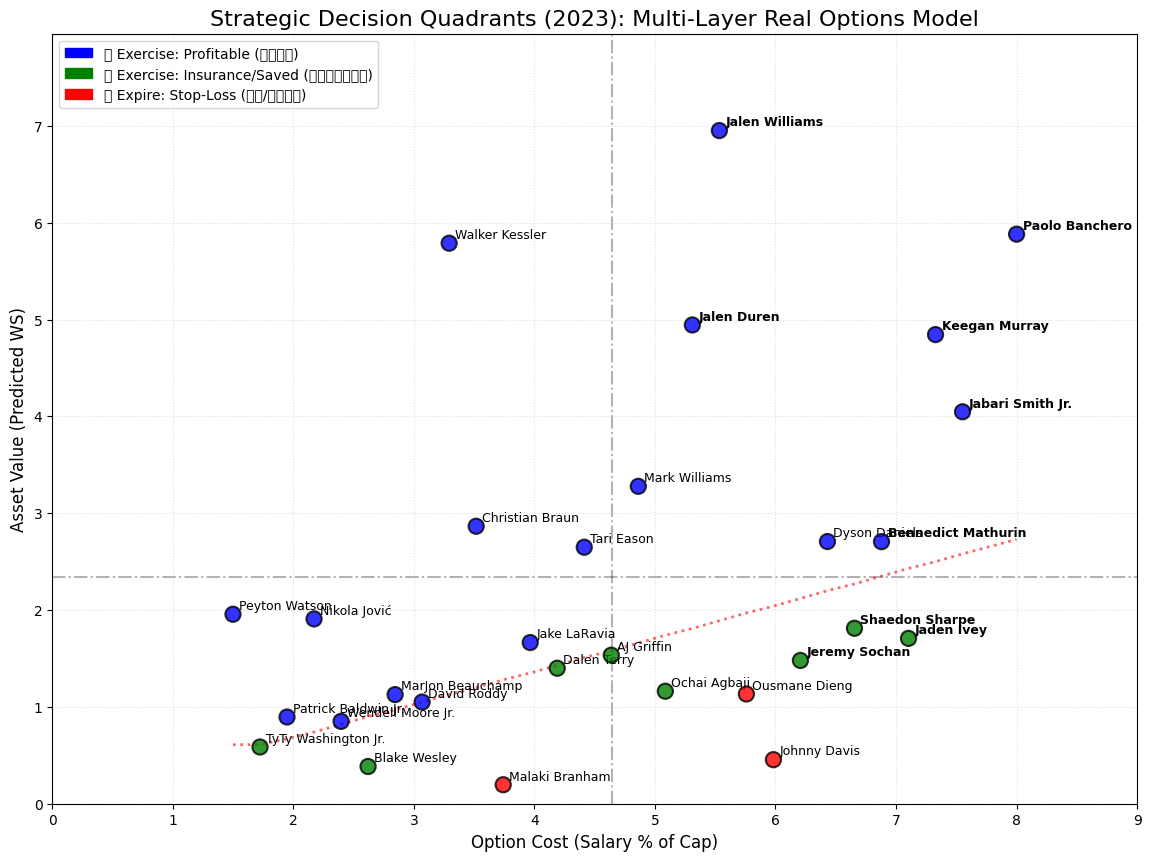


[2023] NBA CONTRACT OPTION STRATEGY REPORT (DECISION ENGINE 6.0)
📊 總分析球員數: 29
🔵 建議執行 (獲利區): 18 名
🟢 建議執行 (保險/救贖區): 8 名
🔴 建議放棄 (絕對止損區): 3 名
--------------------------------------------------------------------------------

💡 [安全網救贖清單] 以下球員因觸發特定防線，系統建議強制保留：
             Player  Pred_WS  Dynamic_Truth_WS  Adjusted_Net_Surplus               decision_reason
     Shaedon Sharpe 1.811862              2.27                 -1.35           🟢 統計容錯 (財務微虧但在誤差區間)
         Jaden Ivey 1.707493              2.43                 -2.11 🟢 商業聲量救場 (超越同梯 70% 基準線 0.085)
         AJ Griffin 1.533957              1.58                 -0.15           🟢 統計容錯 (財務微虧但在誤差區間)
      Jeremy Sochan 1.479581              2.12                 -1.88 🟢 商業聲量救場 (超越同梯 70% 基準線 0.085)
        Dalen Terry 1.399188              1.43                 -0.09           🟢 統計容錯 (財務微虧但在誤差區間)
       Ochai Agbaji 1.161597              1.74                 -1.69           🟢 統計容錯 (財務微虧但在誤差區間)
TyTy Washington Jr. 0.585682              0.61      

In [21]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches

# ==========================================
# 1. 讀取數據與特徵總表合併
# ==========================================
print("📂 正在載入預測數據與 NLP/傷病 特徵總表...")
df_pred = pd.read_csv("NBA_Predicted_WS.csv")
df_features = pd.read_csv("NBA_Player_Final_Master_Features.csv")

df_pred['Player'] = df_pred['Player'].astype(str).str.strip()
df_features['Player'] = df_features['Player'].astype(str).str.strip()

df_all = pd.merge(df_pred, df_features[['Player', 'Worst_Injury_History', 'Star_Power_Index']], on='Player', how='left')
df_all['Worst_Injury_History'] = df_all['Worst_Injury_History'].fillna(0).astype(int)
df_all['Star_Power_Index'] = df_all['Star_Power_Index'].fillna(0)

target_year = 2023
df_plot = df_all[df_all["year_start"] == target_year].copy()


# ==========================================
# 2. 定義系統黃金參數 (Data-Driven Parameters)
# ==========================================
PENALTY_WEIGHT = 0.8  # 傷病風險折價
RMSE_BUFFER = rmse_test     # 模型預測容錯緩衝

# 🌟 核心修正：只針對「該年度 (df_plot)」的新秀，動態計算 PR 70 的商業及格線
DYNAMIC_STAR_POWER_FLOOR = df_plot['Star_Power_Index'].quantile(0.70)
print(f"📈 偵測到 {target_year} 梯次新秀 NLP 聲量分佈，動態商業及格線 (PR 70) 落在：{DYNAMIC_STAR_POWER_FLOOR:.3f}")

# ==========================================
# 3. 實質財務落差計算 (Risk-Adjusted Valuation)
# ==========================================
df_plot['Risk_Penalty_Percent'] = df_plot['Worst_Injury_History'] * PENALTY_WEIGHT
df_plot['Adjusted_Pred_Salary'] = df_plot['Pred_Salary_Share_Percent'] - df_plot['Risk_Penalty_Percent']
df_plot['Adjusted_Net_Surplus'] = df_plot['Adjusted_Pred_Salary'] - df_plot['Est_Cost_Percent']

# ==========================================
# 🌟 4. 嚴格瀑布流判定邏輯 (Waterfall Logic)
# ==========================================
df_plot["plot_color"] = "red"
df_plot["decision_reason"] = "🔴 絕對止損 (未達標準)"

# 關卡 1：絕對獲利區
cond_blue = df_plot["Adjusted_Net_Surplus"] > 0
df_plot.loc[cond_blue, "plot_color"] = "blue"
df_plot.loc[cond_blue, "decision_reason"] = "🔵 絕對獲利 (實力超越成本)"

# 關卡 2：統計容錯區
cond_green_buffer = (df_plot["plot_color"] == "red") & (df_plot["Adjusted_Net_Surplus"] >= -RMSE_BUFFER)
df_plot.loc[cond_green_buffer, "plot_color"] = "green"
df_plot.loc[cond_green_buffer, "decision_reason"] = "🟢 統計容錯 (財務微虧但在誤差區間)"

# 關卡 3：動態機會成本救贖
cond_green_dynamic = (df_plot["plot_color"] == "red") & (df_plot["Pred_WS"] >= df_plot["Dynamic_Truth_WS"])
df_plot.loc[cond_green_dynamic, "plot_color"] = "green"
df_plot.loc[cond_green_dynamic, "decision_reason"] = "🟢 機會成本救贖 (產能大於自由市場替代品)"

# 關卡 4：商業聲量票房救場 (🌟 使用同梯次算出來的 DYNAMIC_STAR_POWER_FLOOR)
cond_green_star = (df_plot["plot_color"] == "red") & (df_plot["Star_Power_Index"] >= DYNAMIC_STAR_POWER_FLOOR) & (df_plot["Adjusted_Net_Surplus"] >= -(RMSE_BUFFER * 1.5))
df_plot.loc[cond_green_star, "plot_color"] = "green"
df_plot.loc[cond_green_star, "decision_reason"] = f"🟢 商業聲量救場 (超越同梯 70% 基準線 {DYNAMIC_STAR_POWER_FLOOR:.3f})"
# ==========================================
# 5. 繪圖與視覺化
# ==========================================
plt.figure(figsize=(14, 10))

x = df_plot["Est_Cost_Percent"]
y = df_plot["Pred_WS"]

# 散點圖
plt.scatter(x, y, c=df_plot["plot_color"], s=120, alpha=0.8, edgecolors="black", linewidth=1.5, zorder=5)

# --- 繪製輔助線 ---
# 1. 表現及格線 (動態斜線)
df_sorted = df_plot.sort_values("Est_Cost_Percent")
plt.plot(df_sorted["Est_Cost_Percent"], df_sorted["Dynamic_Truth_WS"], 
         color="red", linestyle=":", linewidth=2, alpha=0.6, 
         label="Dynamic WS Ceiling (Safety Net)", zorder=2)

# 2. 平均成本線 
plt.axvline(x.mean(), color="black", linestyle="-.", alpha=0.3, label=f"Avg Cost ({x.mean():.2f}%)", zorder=1)

# 3. 平均表現線 
plt.axhline(y.mean(), color="black", linestyle="-.", alpha=0.3, label=f"Avg WS ({y.mean():.2f})", zorder=1)

# 標註球員名稱
for i, row in df_plot.iterrows():
    plt.text(row["Est_Cost_Percent"] + 0.05, row["Pred_WS"] + 0.05, row["Player"], fontsize=9, 
             fontweight='bold' if row['Star_Power_Index'] >= DYNAMIC_STAR_POWER_FLOOR else 'normal')

plt.xlabel("Option Cost (Salary % of Cap)", fontsize=12)
plt.ylabel("Asset Value (Predicted WS)", fontsize=12)
plt.title(f"Strategic Decision Quadrants ({target_year}): Multi-Layer Real Options Model", fontsize=16)

# 圖例
blue_patch = mpatches.Patch(color='blue', label='🔵 Exercise: Profitable (絕對獲利)')
green_patch = mpatches.Patch(color='green', label='🟢 Exercise: Insurance/Saved (多層防護網救回)')
red_patch = mpatches.Patch(color='red', label='🔴 Expire: Stop-Loss (水貨/溢價止損)')
plt.legend(handles=[blue_patch, green_patch, red_patch], loc='upper left')

plt.grid(True, linestyle=':', alpha=0.4)
plt.xlim(0, x.max() + 1)
plt.ylim(0, y.max() + 1)

plt.savefig('Contract Decision.png')
plt.show()

# ==========================================
# 6. 自動化決策報告
# ==========================================
print("\n" + "="*80)
print(f"[{target_year}] NBA CONTRACT OPTION STRATEGY REPORT (DECISION ENGINE 6.0)")
print("="*80)

total_players = len(df_plot)
blue_count = len(df_plot[df_plot["plot_color"] == "blue"])
green_count = len(df_plot[df_plot["plot_color"] == "green"])
red_count = len(df_plot[df_plot["plot_color"] == "red"])

print(f"📊 總分析球員數: {total_players}")
print(f"🔵 建議執行 (獲利區): {blue_count} 名")
print(f"🟢 建議執行 (保險/救贖區): {green_count} 名")
print(f"🔴 建議放棄 (絕對止損區): {red_count} 名")
print("-" * 80)

# 抓出「被防護網救回」的球員
saved_players = df_plot[df_plot["plot_color"] == "green"].copy()

if not saved_players.empty:
    print(f"\n💡 [安全網救贖清單] 以下球員因觸發特定防線，系統建議強制保留：")
    disp_saved = saved_players[["Player", "Pred_WS", "Dynamic_Truth_WS", "Adjusted_Net_Surplus", "decision_reason"]].sort_values("Pred_WS", ascending=False)
    # 四捨五入方便閱讀
    disp_saved["Dynamic_Truth_WS"] = disp_saved["Dynamic_Truth_WS"].round(2)
    disp_saved["Adjusted_Net_Surplus"] = disp_saved["Adjusted_Net_Surplus"].round(2)
    print(disp_saved.to_string(index=False))

print("\n" + "!"*25 + " 🛑 CRITICAL STOP-LOSS LIST " + "!"*25)
red_zone = df_plot[df_plot["plot_color"] == "red"].copy()

if red_zone.empty:
    print("無絕對止損球員")
else:
    red_zone_sorted = red_zone[["Player", "Pred_WS", "Dynamic_Truth_WS", "Worst_Injury_History", "Adjusted_Net_Surplus"]].sort_values("Adjusted_Net_Surplus")
    red_zone_sorted["Dynamic_Truth_WS"] = red_zone_sorted["Dynamic_Truth_WS"].round(2)
    red_zone_sorted["Adjusted_Net_Surplus"] = red_zone_sorted["Adjusted_Net_Surplus"].round(2)
    print("以下球員經風險校正後嚴重虧損，且無任何商業或產能特權，強烈建議拒絕執行：")
    print("-" * 85)
    print(red_zone_sorted.to_string(index=False))
    print("-" * 85)

In [22]:
import os
import pandas as pd

def export_declined_players(df_plot, target_year, output_filename="Declined_Players_Report.csv"):
    """
    獨立的匯出模組：將瀑布流決策中判定為「絕對止損 (紅區)」的球員名單匯出至 CSV。
    """
    print(f"📥 啟動匯出模組：準備擷取 {target_year} 年梯次未執行名單...")
    
    # 1. 只篩選出被判定為紅區 (絕對止損) 的球員
    red_zone = df_plot[df_plot["plot_color"] == "red"].copy()
    
    if red_zone.empty:
        print(f"✅ {target_year} 年無絕對止損球員，結束匯出作業。")
        return

    # 2. 依照虧損程度排序 (虧最多的在最上面)
    red_zone_sorted = red_zone.sort_values("Adjusted_Net_Surplus", ascending=True)
    
    # 3. 整理要輸出的欄位，並在最前面插入「年份」
    df_declined = red_zone_sorted.copy()
    df_declined.insert(0, "Draft_Year", target_year)
    
    # 挑選寫入報表的關鍵特徵
    save_cols = [
        "Draft_Year", 
        "Player", 
        "Pred_WS", 
        "Dynamic_Truth_WS", 
        "Worst_Injury_History", 
        "Star_Power_Index",
        "Adjusted_Net_Surplus", 
        "Year3_WS"
    ]
    df_to_save = df_declined[save_cols]
    
    # 四捨五入讓報表更美觀
    df_to_save = df_to_save.round(3)

    # 4. 存檔邏輯 (支援自動往下接續寫入，不會覆蓋舊年份)
    file_exists = os.path.isfile(output_filename)
    df_to_save.to_csv(output_filename, mode='a', index=False, header=not file_exists, encoding='utf-8-sig')
    
    print("\n" + "="*60)
    print(f"💾 [匯出成功] 已將 {len(df_to_save)} 名淘汰球員寫入：{output_filename}")
    print("="*60)
    
    # 顯示前幾筆確認結果
    print(df_to_save.head().to_string(index=False))

# ==========================================
# 執行匯出 (只要你前面的主程式跑完，有了 df_plot 和 target_year，就能直接呼叫)
# ==========================================
export_declined_players(df_plot, target_year)

📥 啟動匯出模組：準備擷取 2023 年梯次未執行名單...

💾 [匯出成功] 已將 3 名淘汰球員寫入：Declined_Players_Report.csv
 Draft_Year         Player  Pred_WS  Dynamic_Truth_WS  Worst_Injury_History  Star_Power_Index  Adjusted_Net_Surplus  Year3_WS
       2023   Johnny Davis    0.455              2.04                     0               0.0                -4.651       0.1
       2023 Malaki Branham    0.196              1.28                     0               0.0                -3.167       0.1
       2023  Ousmane Dieng    1.133              1.97                     0               0.0                -2.442       0.9
